# Road Segmentation — UNet
Semantic segmentation of roads from aerial imagery using a lightweight UNet trained on the DeepGlobe Road Extraction Dataset.

In [ ]:
# Necessary Imports

import numpy as np
import random
import matplotlib.pyplot as plt

import os
import cv2
import albumentations as A

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import TensorDataset, DataLoader, random_split

In [ ]:
# Seeding for reproducible results

seed = 42

torch.manual_seed(seed)
np.random.seed(seed)
random.seed(seed)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

## Data Loading
- Loads satellite images and corresponding road masks from DeepGlobe training set.        
- Masks binarized (0=background, 1=road) and both resized to 256×256.     
- Class imbalance handled via pos_weight in loss function.

In [ ]:
# Load Datasets
IMG_SIZE = (256, 256)
VALID_EXT = {'.jpg', '.jpeg', '.png', '.tif', '.tiff'}
def load_images2(class_folder, img_size=IMG_SIZE, limit=100):
    count = 0
    X = []

    for file in os.listdir(class_folder):
        if count >= limit:
            break
        img_path = os.path.join(class_folder, file)

        # Read image (BGR)
        img = cv2.imread(img_path) 

        if img is None:
            continue  # skip corrupted files

        img = cv2.resize(img, img_size) # Resizing images

        X.append(img)
        count += 1

    return np.array(X)

In [23]:
train_folder = "Datasets/road/train"
test_folder = "Datasets/road/test"

train_img = []
train_label = []

image_files = sorted([f for f in os.listdir(train_folder) if f.endswith('_sat.jpg')])
mask_files = sorted([f for f in os.listdir(train_folder) if f.endswith('_mask.png')])

LIMIT = 1000 

for img_file, mask_file in zip(image_files[:LIMIT], mask_files[:LIMIT]):
    if os.path.splitext(img_file)[1].lower() not in VALID_EXT:
        continue
    img = cv2.imread(os.path.join(train_folder, img_file))
    mask = cv2.imread(os.path.join(train_folder, mask_file), cv2.IMREAD_GRAYSCALE)
    
    if img is None or mask is None:
        continue
    
    img = cv2.resize(img, IMG_SIZE)
    mask = cv2.resize(mask, IMG_SIZE, interpolation=cv2.INTER_NEAREST)
    binary_mask = (mask > 127).astype(np.uint8)
    binary_mask = np.expand_dims(binary_mask, axis=0)

    train_img.append(img)
    train_label.append(binary_mask)

In [ ]:
# Check dataset shape
X_train = np.array(train_img)
Y_train = np.array(train_label)
X_test = load_images2("Datasets/road/test")

print("X train shape: ",X_train.shape)
print("Y Train shape: ",Y_train.shape)
print("X Test shape: ",X_test.shape)

print("Classes: ",np.unique(Y_train))

X train shape:  (1000, 256, 256, 3)
Y Train shape:  (1000, 1, 256, 256)
X Test shape:  (100, 256, 256, 3)
Classes:  [0 1]


## Dataset Preparation

- Images normalized to [0,1]
- Data converted to PyTorch tensors
- Train-validation split applied (80-20)
- DataLoader used for batching and shuffling

In [26]:
# Normalizing pixel values to prevent exploding gradients
X_train = (X_train / 255.0).astype(np.float32)
X_test = (X_test / 255.0).astype(np.float32)

In [27]:
# Convert to Pytorch Format

X_train_torch = torch.tensor(X_train, dtype=torch.float32).permute(0, 3, 1, 2)
Y_train_torch = torch.tensor(Y_train, dtype=torch.float32)

X_test_torch = torch.tensor(X_test, dtype=torch.float32).permute(0, 3, 1, 2)

print("Train X shape:", X_train_torch.shape)
print("Train Y shape:", Y_train_torch.shape)
print("Test X shape:", X_test_torch.shape)

Train X shape: torch.Size([1000, 3, 256, 256])
Train Y shape: torch.Size([1000, 1, 256, 256])
Test X shape: torch.Size([100, 3, 256, 256])


In [28]:
# Create DataLoader

train_dataset = TensorDataset(X_train_torch, Y_train_torch)

train_size = int(0.8 * len(train_dataset))
val_size = len(train_dataset) - train_size

train_dataset, val_dataset = random_split(
    train_dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=4)

## Model Architecture — UNet
Encoder-decoder with skip connections for pixel-wise road segmentation.
- **Encoder:** Two double-conv blocks (64, 128 channels) with MaxPool downsampling
- **Bottleneck:** 256 channels with Dropout(0.3) for regularization  
- **Decoder:** Transposed convolutions with skip connections from encoder
- **Output:** Single channel sigmoid for binary road/non-road prediction

In [29]:
def double_conv(in_c, out_c):
    return nn.Sequential(
        nn.Conv2d(in_c, out_c, kernel_size=3, padding=1),
        nn.BatchNorm2d(out_c),
        nn.ReLU(inplace=True),
        nn.Conv2d(out_c, out_c, kernel_size=3, padding=1),
        nn.BatchNorm2d(out_c),
        nn.ReLU(inplace=True)
    )

In [ ]:
class UNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=1):
        super(UNet, self).__init__()

        # Encoder (Downsampling)
        self.enc1 = double_conv(in_channels, 64)
        self.enc2 = double_conv(64, 128)
        self.pool = nn.MaxPool2d(2)
        
        # Bottleneck
        self.bottleneck = nn.Sequential(
            double_conv(128, 256),
            nn.Dropout2d(0.3)
        )
    
        # Decoder (Upsampling)
        self.up2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.dec2 = double_conv(256, 128) 
        
        self.up1 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.dec1 = double_conv(128, 64) 
        
        # Output layer
        self.final_conv = nn.Conv2d(64, out_channels, kernel_size=1)

    def forward(self, x):
        # Encoder
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        
        # Bottleneck
        b = self.bottleneck(self.pool(e2))
        
        # Decoder with Skip Connections
        d2 = self.up2(b)
        d2 = torch.cat([d2, e2], dim=1) # Concatenate along channel dim
        d2 = self.dec2(d2)
        
        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1)
        
        return self.final_conv(d1)

## Training
- Combined BCE + Dice loss to handle class imbalance and optimize overlap.
- Reduce LR On Plateau scheduler halves lr if validation Dice stagnates for 3 epochs.
- Best model saved to unet_best.pth based on validation Dice score.

In [ ]:
# Training setup

model = UNet()
model.load_state_dict(torch.load('unet_best.pth', weights_only=True))

# Set positional weight to use as training parameter
num_pos = np.sum(Y_train == 1)
num_neg = np.sum(Y_train == 0)
pos_weight = num_neg / (num_pos + 1e-6) * 1.5
pos_weight_tensor = torch.tensor(pos_weight, dtype=torch.float32)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
pos_weight_tensor = pos_weight_tensor.to(device)

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight_tensor)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
# If improvement stalls reduce lr
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='max', factor=0.5, patience=3
)

In [ ]:
# Calculate dice score for validation
def dice_score(pred, target):
    pred = torch.sigmoid(pred)
    intersection = (pred * target).sum(dim=(1,2,3))
    union = pred.sum(dim=(1,2,3)) + target.sum(dim=(1,2,3))

    dice = (2 * intersection + 1e-6) / (union + 1e-6)
    return dice.mean()

In [ ]:
# Calculate Dice loss for training
def dice_loss(pred, target):
    pred = torch.sigmoid(pred)

    intersection = (pred * target).sum(dim=(1,2,3))
    union = pred.sum(dim=(1,2,3)) + target.sum(dim=(1,2,3))

    dice = (2 * intersection + 1e-6) / (union + 1e-6)
    return 1 - dice.mean()

In [35]:
# Training Loop

epochs = 15
val_dices = []
best_dice = 0

for epoch in range(epochs):

    # TRAINING
    model.train()   # sets model to training mode -> affects dropout(enabled), BatchNorm
    correct = 0
    total = 0
    running_loss = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()   # clears old gradients
        outputs = model(images)

        bce = criterion(outputs, labels)
        d_loss = dice_loss(outputs, labels)

        loss = 0.5 * bce + 0.5 * d_loss

        loss.backward()     # Gradients computed
        optimizer.step()    # Gradients updated

        running_loss += loss.item()

    # VALIDATION 
    model.eval()        # Sets model to evaluation mode -> dropout(disabled), BatchNorm uses previously stored mean and variance instead of computing a new one
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        raw_dice = 0
        mean_preds = []

        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            probs = torch.sigmoid(outputs)
            raw_dice += dice_score(outputs, labels)
            mean_preds.append(probs.mean().item())

        val_dice_raw = raw_dice / len(val_loader)

    if val_dice_raw > best_dice:    # Model with best performance gets saved for future use
        best_dice = val_dice_raw
        torch.save(model.state_dict(), 'unet_best.pth')

    val_dices.append(val_dice_raw)
    scheduler.step(val_dice_raw)

    print(f"Epoch {epoch+1}, Val Dice: {val_dice_raw:.4f}, Mean prediction: {np.mean(mean_preds):.4f}")

Epoch 1, Val Dice: 0.1400, Mean prediction: 0.3981
Epoch 2, Val Dice: 0.1642, Mean prediction: 0.3263
Epoch 3, Val Dice: 0.1933, Mean prediction: 0.2712
Epoch 4, Val Dice: 0.2465, Mean prediction: 0.1995
Epoch 5, Val Dice: 0.2580, Mean prediction: 0.1921
Epoch 6, Val Dice: 0.1883, Mean prediction: 0.3097
Epoch 7, Val Dice: 0.1658, Mean prediction: 0.3944
Epoch 8, Val Dice: 0.2780, Mean prediction: 0.1942
Epoch 9, Val Dice: 0.2830, Mean prediction: 0.2068
Epoch 10, Val Dice: 0.3106, Mean prediction: 0.1684
Epoch 11, Val Dice: 0.3112, Mean prediction: 0.1589
Epoch 12, Val Dice: 0.3619, Mean prediction: 0.1227
Epoch 13, Val Dice: 0.3608, Mean prediction: 0.1335
Epoch 14, Val Dice: 0.3122, Mean prediction: 0.1900
Epoch 15, Val Dice: 0.3040, Mean prediction: 0.1714


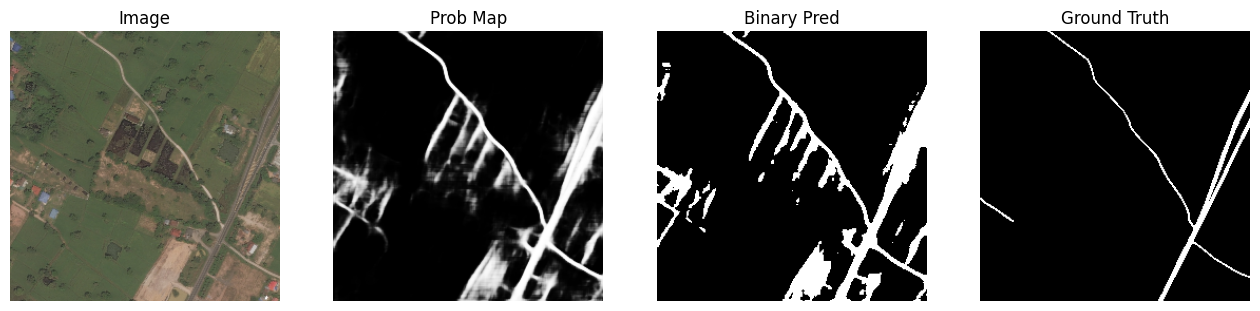

In [36]:
# Check model performace on a testing image and visualize result

img = images[0].detach().cpu().permute(1,2,0).numpy()
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
prob = probs[0][0].detach().cpu().numpy()
pred = (prob > 0.5).astype(np.uint8)
gt = labels[0][0].detach().cpu().numpy()

# Display image vs Probability map vs Binary Predictions vs Ground Truth
fig, axs = plt.subplots(1,4, figsize=(16,4))

axs[0].imshow(img)
axs[0].set_title("Image")

axs[1].imshow(prob, cmap='gray')
axs[1].set_title("Prob Map")

axs[2].imshow(pred, cmap='gray')
axs[2].set_title("Binary Pred")

axs[3].imshow(gt, cmap='gray')
axs[3].set_title("Ground Truth")

for ax in axs:
    ax.axis('off')

plt.show()

## Inference
Segments topdown_image.png and saves binary road mask as segmented_mask.png
for use in the A* pathfinding pipeline.

In [37]:
# Segment stitched map using trained model
def segment_image(model, image, device):
    model.eval()

    img = cv2.resize(image, (256, 256))
    img = img / 255.0
    img = img.astype(np.float32)

    img_t = torch.tensor(img).permute(2,0,1).unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(img_t)
        prob = torch.sigmoid(output)[0,0].cpu().numpy()

    return prob

In [45]:
# Segment image and save binary predictions mask

# Paths
input_path = "results"
output_path = "segmented_results"
os.makedirs(output_path, exist_ok=True)

# Load model 
model = UNet()
model.load_state_dict(torch.load('unet_best.pth', weights_only=True))
model.to(device)
model.eval()

for file in os.listdir(input_path):

    if not file.endswith(".png"):
        continue

    img_path = os.path.join(input_path, file)
    print(f"Processing {file}...")

    image = cv2.imread(img_path)

    if image is None:
        print("Skipping corrupted image")
        continue

    # ---- Segmentation ----
    prob = segment_image(model, image, device)

    mask = (prob > 0.5).astype(np.uint8) * 255

    # Resize back to original size
    mask = cv2.resize(
        mask,
        (image.shape[1], image.shape[0]),
        interpolation=cv2.INTER_NEAREST
    )

    # Remove tiny noise blobs
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)

    cleaned_mask = np.zeros_like(mask)

    for i in range(1, num_labels):  # skip background
        area = stats[i, cv2.CC_STAT_AREA]
        if area > 500:  
            cleaned_mask[labels == i] = 255

    mask = cleaned_mask
    
    # ---- Morphology ----
    kernel = np.ones((3,3), np.uint8)
    kernel_big = np.ones((5,5), np.uint8)

    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)   # remove noise
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)  # fill gaps
    mask = cv2.dilate(mask, kernel_big, iterations=1)       # slightly thicken roads
    
    # Remove tiny noise blobs again
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)

    cleaned_mask = np.zeros_like(mask)

    for i in range(1, num_labels):  # skip background
        area = stats[i, cv2.CC_STAT_AREA]
        if area > 500:  
            cleaned_mask[labels == i] = 255

    # ---- Save ----
    name = file.replace("_topdown.png", "")

    cv2.imwrite(os.path.join(output_path, f"{name}_mask.png"), cleaned_mask)

    print(f"Saved: {name}_mask.png")

Processing a_8_topdown.png...
Saved: a_8_mask.png
Processing a_16_topdown.png...
Saved: a_16_mask.png
Processing a_1_topdown.png...
Saved: a_1_mask.png
Processing a_4_topdown.png...
Saved: a_4_mask.png
Processing a_13_topdown.png...
Saved: a_13_mask.png
Processing a_19_topdown.png...
Saved: a_19_mask.png
Processing a_10_topdown.png...
Saved: a_10_mask.png
Processing a_7_topdown.png...
Saved: a_7_mask.png
Processing a_2_topdown.png...
Saved: a_2_mask.png
Processing a_15_topdown.png...
Saved: a_15_mask.png
Processing a_12_topdown.png...
Saved: a_12_mask.png
Processing a_5_topdown.png...
Saved: a_5_mask.png
Processing a_20_topdown.png...
Saved: a_20_mask.png
Processing a_0_topdown.png...
Saved: a_0_mask.png
Processing a_17_topdown.png...
Saved: a_17_mask.png
Processing a_9_topdown.png...
Saved: a_9_mask.png
Processing a_14_topdown.png...
Saved: a_14_mask.png
Processing a_3_topdown.png...
Saved: a_3_mask.png
Processing a_6_topdown.png...
Saved: a_6_mask.png
Processing a_11_topdown.png...
S

## Results: 
With 500 images and 3 Convolutional layers:          
`Epoch 14, Val Dice: 0.3829, Mean prediction: 0.1740 `            

With 1000 images and 2 Convolutional layers:                
`Epoch 18, Val Dice: 0.4029, Mean prediction: 0.1206`             